# TOPIC 1: Explainable Machine Learning for Gallstone Disease

**Dataset:** UCI Gallstone Disease Dataset (`gallstone-1`)   

## In this Notebook

1. **Exploratory Data Analysis (EDA):** Inspect dataset dimensions, feature distributions, and class balance.
2. **Data Preprocess:** Apply feature scaling and stratified test split ($80/20$).
3. **Model Development:** Train 4 classifiers (Logistic Regression, Random Forest, SVM, XGBoost) with stratified cross-validation.
4. **Evaluation:** Compare performance metrics (Accuracy, Precision, Recall, F1-Score, ROC-AUC) and plot confusion matrices.
5. **Model Export:** Save the top-performing model (`best_model.joblib`) to the `dataset/` directory for SHAP/LIME explainability analysis.

In [28]:
#NECESARY LIBRARYS FROM THE COURSE

import os
import joblib

#1.2: Introduction to Python Libraries for Machine Learning
#data handling, visualization, and basic preprocessing
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler


#3.2.1: Introduction to Classification (Baseline)
from sklearn.linear_model import LogisticRegression


#3.2.3: Evaluation Metrics in Classification
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

#3.2.4: Decision Trees & Tree Ensembles
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier


#3.2.5: Support Vector Machine (SVM)
from sklearn.svm import SVC

#for explainability analysis
import shap

#to avoid warnings related to specific functions or old versions
import warnings
warnings.filterwarnings('ignore')

In [29]:
#uploading the dataset from the location of the excel on the project

#dataset route to the excel
data_path = os.path.join('..', 'dataset', 'dataset-uci.xlsx')

#uploading the dataset with calamine
df = pd.read_excel(data_path, engine='calamine')

#printing to check the succes
print(f"Dataset uploaded. Size: {df.shape}")
df.head()

Dataset uploaded. Size: (319, 39)


,Gallstone Status,Age,Gender,Comorbidity,Coronary Artery Disease (CAD),Hypothyroidism,Hyperlipidemia,Diabetes Mellitus (DM),Height,Weight,...,High Density Lipoprotein (HDL),Triglyceride,Aspartat Aminotransferaz (AST),Alanin Aminotransferaz (ALT),Alkaline Phosphatase (ALP),Creatinine,Glomerular Filtration Rate (GFR),C-Reactive Protein (CRP),Hemoglobin (HGB),Vitamin D
0,0,50,0,0,0,0,0,0,185,92.8,...,40.0,134.0,20.0,22.0,87.0,0.82,112.47,0.0,16.0,33.0
1,0,47,0,1,0,0,0,0,176,94.5,...,43.0,103.0,14.0,13.0,46.0,0.87,107.10,0.0,14.4,25.0
2,0,61,0,0,0,0,0,0,171,91.1,...,43.0,69.0,18.0,14.0,66.0,1.25,65.51,0.0,16.2,30.2
3,0,41,0,0,0,0,0,0,168,67.7,...,59.0,53.0,20.0,12.0,34.0,1.02,94.10,0.0,15.4,35.4
4,0,42,0,0,0,0,0,0,178,89.6,...,30.0,326.0,27.0,54.0,71.0,0.82,112.47,0.0,16.8,40.6


1. **Exploratory Data Analysis (EDA):** Inspect dataset dimensions, feature distributions, and class balance.

Total missing values: 0

Target Class Distribution
Gallstone Status
0    161
1    158
Name: count, dtype: int64


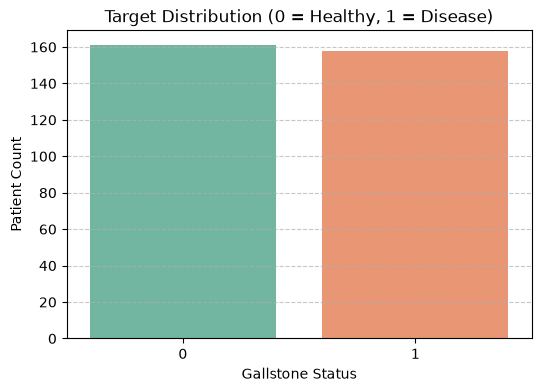

In [30]:
#setting the target
target_col = 'Gallstone Status'

#checking missing values
print(f"Total missing values: {df.isnull().sum().sum()}")

#Check target variable class balance
print("\nTarget Class Distribution")
print(df[target_col].value_counts())

#plotting class balance
plt.figure(figsize=(6, 4))
sns.countplot(x=target_col, data=df, hue=target_col, palette='Set2', legend=False)
plt.title('Target Distribution (0 = Healthy, 1 = Disease)')
plt.xlabel('Gallstone Status')
plt.ylabel('Patient Count')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

2. **Data Preprocess:** Apply feature scaling and stratified test split ($80/20$).

In [31]:
#separate features and target
X = df.drop(columns=[target_col])
y = df[target_col]

#stratified Train/Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.20, 
    random_state=42, 
    stratify=y
)

#feature scaling with StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

#save fitted scaler for future inference
scaler_path = os.path.join('..', 'dataset', 'scaler.joblib')
joblib.dump(scaler, scaler_path)

print(f"Split complete: {X_train_scaled.shape[0]} train samples, {X_test_scaled.shape[0]} test samples.")
print(f"Scaler saved to: {scaler_path}")

Split complete: 255 train samples, 64 test samples.
Scaler saved to: ..\dataset\scaler.joblib


3. **Model Development:** Train 4 classifiers (Logistic Regression, Random Forest, SVM, XGBoost) with stratified cross-validation.

In [32]:
#dictionary for the 4 models
models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Support Vector Machine': SVC(probability=True, random_state=42),
    'XGBoost': XGBClassifier(eval_metric='logloss', random_state=42)
}

#looping the dictionary of models through the data
print("training classification models")
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    print(f"{name} trained.")

training classification models
Logistic Regression trained.
Random Forest trained.
Support Vector Machine trained.
XGBoost trained.


4. **Evaluation:** Compare performance metrics (Accuracy, Precision, Recall, F1-Score, ROC-AUC) and plot confusion matrices.


--- Model Performance Summary ---
                    Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
0                 XGBoost    0.8594     0.9259  0.7812    0.8475   0.8916
1           Random Forest    0.8125     0.8125  0.8125    0.8125   0.8740
2     Logistic Regression    0.7812     0.8000  0.7500    0.7742   0.8828
3  Support Vector Machine    0.7500     0.7667  0.7188    0.7419   0.8838


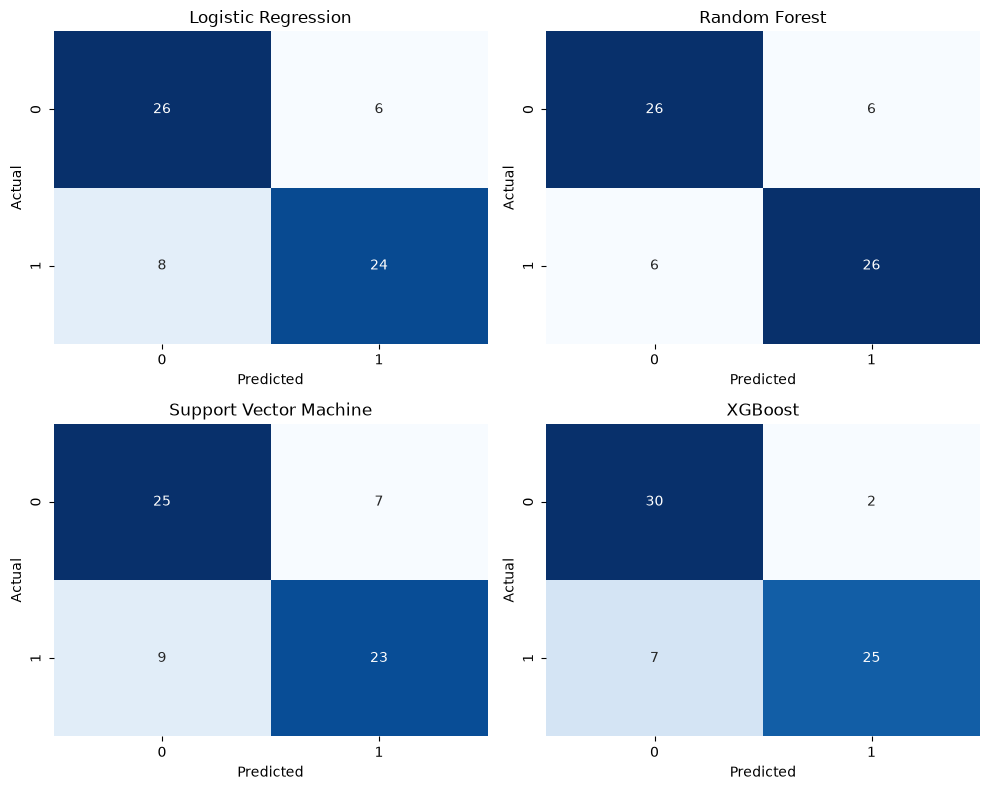

In [33]:
#list to store the results
results = []

#looping thorugh the models to seee the different results
for name, model in models.items():
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]

    #we append the results of the 5 calculated metrics into the list to compare trugh agaisnt predictions
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba)
    })

#metrics summary
results_df = pd.DataFrame(results).sort_values(by='F1-Score', ascending=False).reset_index(drop=True)
print("\n--- Model Performance Summary ---")
print(results_df.round(4))

#plotting confusion matrix's
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.flatten()

#looping through the models and plotting the confusion matrix
for idx, (name, model) in enumerate(models.items()):
    y_pred = model.predict(X_test_scaled)
    cm = confusion_matrix(y_test, y_pred)
    
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False)
    axes[idx].set_title(f'{name}')
    axes[idx].set_xlabel('Predicted')
    axes[idx].set_ylabel('Actual')

#plotting the results of the confusion matrix
plt.tight_layout()
plt.show()

5. **Model Export:** Save the top-performing model (`best_model.joblib`) to the `dataset/` directory for SHAP/LIME explainability analysis.

In [34]:
#seeing which one is the top-performing model based on the highest F1-Score
best_model_name = results_df.iloc[0]['Model']
best_model = models[best_model_name]

#define the output path in dataset/ directory
best_model_path = os.path.join('..', 'dataset', 'best_model.joblib')

#saving model binary using joblib
joblib.dump(best_model, best_model_path)

#printing the results
print(f"\n Best Model: '{best_model_name}' (F1-Score: {results_df.iloc[0]['F1-Score']:.4f})")
print(f"Model successfully exported to: {best_model_path} for SHAP analysis.")


 Best Model: 'XGBoost' (F1-Score: 0.8475)
Model successfully exported to: ..\dataset\best_model.joblib for SHAP analysis.


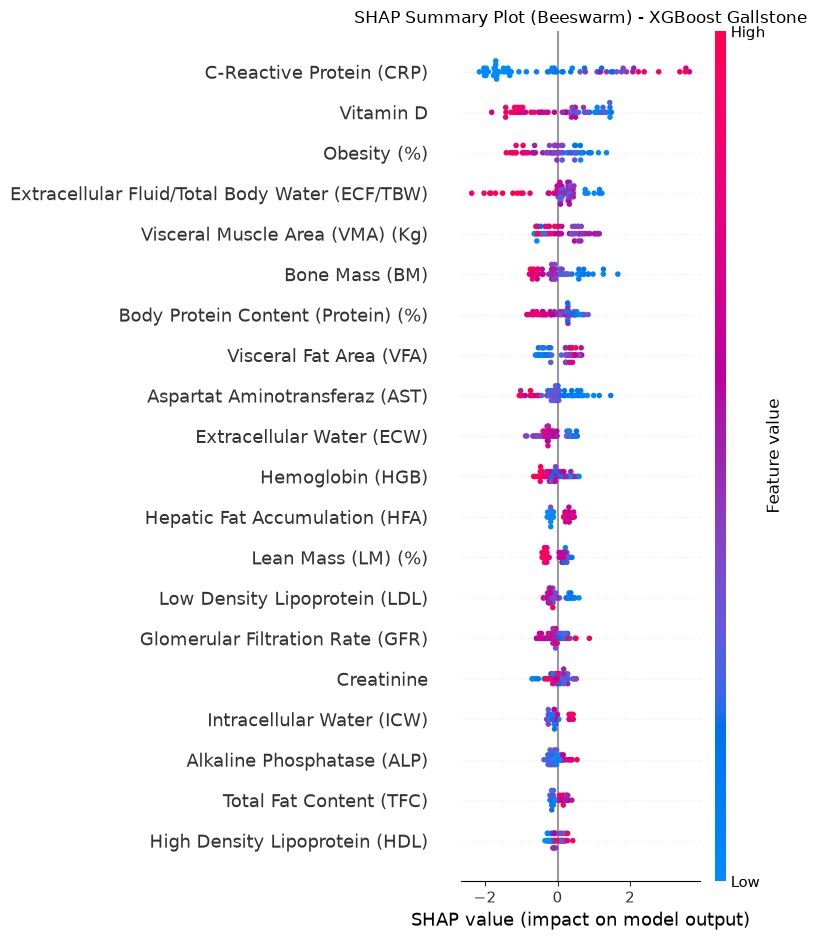

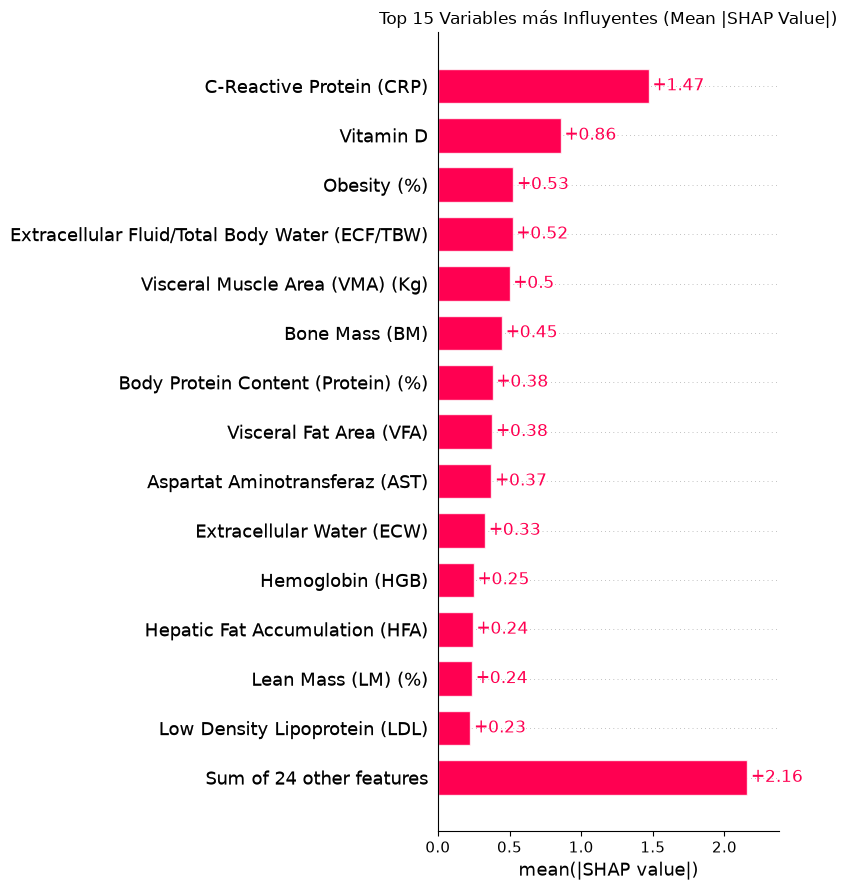

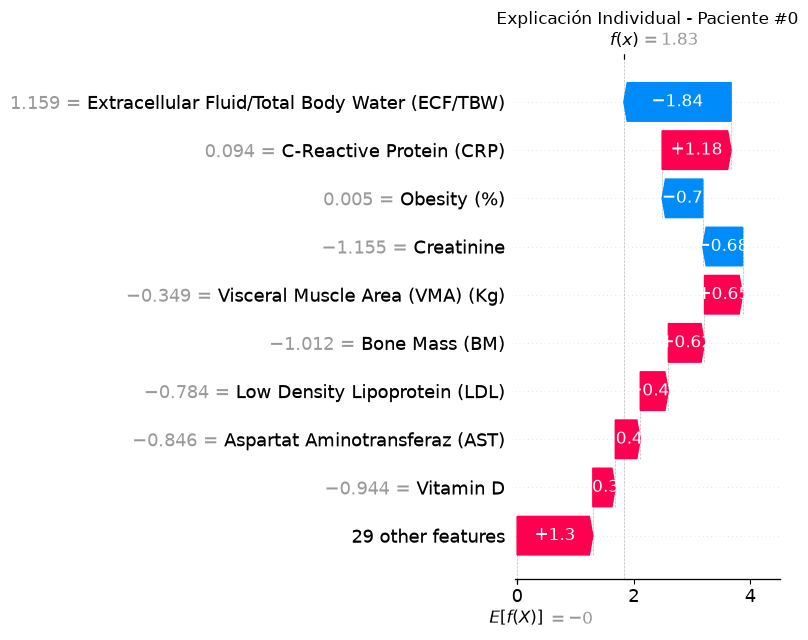

In [35]:
#load the model and the scaler
model_path = os.path.join('..', 'dataset', 'best_model.joblib')
scaler_path = os.path.join('..', 'dataset', 'scaler.joblib')

best_model = joblib.load(model_path)
scaler = joblib.load(scaler_path)

#initialize shap
explainer = shap.TreeExplainer(best_model)
shap_values = explainer(X_test_scaled)
shap_values.feature_names = list(X.columns)

#plotting summary Beeswarm
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_test_scaled, feature_names=list(X.columns), show=False)
plt.title('SHAP Summary Plot (Beeswarm) - XGBoost Gallstone', fontsize=12)
plt.tight_layout()
plt.savefig('shap_summary.png', dpi=300, bbox_inches='tight')  # <--- Guarda la imagen
plt.show()

#plotting shap feature importance bar
plt.figure(figsize=(10, 6))
shap.plots.bar(shap_values, max_display=15, show=False)
plt.title('Top 15 Variables más Influyentes (Mean |SHAP Value|)', fontsize=12)
plt.tight_layout()
plt.savefig('shap_bar.png', dpi=300, bbox_inches='tight')  # <--- Guarda la imagen
plt.show()

#plotting shap waterfall plot
sample_idx = 0
plt.figure(figsize=(8, 6))
shap.plots.waterfall(shap_values[sample_idx], max_display=10, show=False)
plt.title(f'Explicación Individual - Paciente #{sample_idx}', fontsize=12)
plt.tight_layout()
plt.savefig('shap_waterfall.png', dpi=300, bbox_inches='tight')  # <--- Guarda la imagen
plt.show()